Welcome to Kernal about Cohort Analysis (Retention over User & Product Lifetime) which we especially use more in E-commerce website, and Application Mobile

# Cohort Analysis (Retention over User & Product Lifetime)

**A cohort** is a group of subjects who share a defining characteristic[cite: 1]. We can observe how a cohort behaves across time and compare it to other cohorts[cite: 1]. Cohorts are used in medicine, psychology, econometrics, ecology and many other areas to perform a cross-section (compare difference across subjects) at intervals through time[cite: 1].

**Types of cohorts:**[cite: 1]

* **Time Cohorts** are customers who signed up for a product or service during a particular time frame[cite: 1]. Analyzing these cohorts shows the customers' behavior depending on the time they started using the company's products or services[cite: 1]. The time may be monthly or quarterly even daily[cite: 1].
* **Behavior cohorts** are customers who purchased a product or subscribed to a service in the past[cite: 1]. It groups customers by the type of product or service they signed up[cite: 1]. Customers who signed up for basic level services might have different needs than those who signed up for advanced services[cite: 1]. Understanding the needs of the various cohorts can help a company design custom-made services or products for particular segments[cite: 1].
* **Size cohorts** refer to the various sizes of customers who purchase company's products or services[cite: 1]. This categorization can be based on the amount of spending in some periodic time after acquisition or the product type that the customer spent most of their order amount in some period of time[cite: 1].

In [4]:
# ==========================================
# LIBRARIES IMPORT & SETUP
# ==========================================
import numpy as np
import pandas as pd
import datetime as dt
import time
import warnings

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning Modules
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Global Settings & Styling
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# ==========================================
# DATA LOADING
# ==========================================
# Update file path if needed (e.g., 'Online-Retail.xlsx' or './Online Retail.xlsx')
df = pd.read_excel("Online-Retail.xlsx")

# Display initial rows
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:

def load_and_clean_data(file_path):
    """
    Loads raw transaction data and applies essential data cleaning,
    cancellation filtering, and feature engineering pipelines.
    """
    print("=" * 60)
    print("STARTING STEP 1: LOAD & CLEAN DATA")
    print("=" * 60)
    print("--- 1. Loading Dataset ---")
    
    # Read dataset (handles Excel or CSV)
    if file_path.endswith('.xlsx') or file_path.endswith('.xls'):
        df = pd.read_excel(file_path)
    else:
        df = pd.read_csv(file_path, encoding='ISO-8859-1')
        
    initial_shape = df.shape
    print(f"Initial Dataset Shape: {initial_shape[0]} rows, {initial_shape[1]} columns")

    # Clean column header whitespaces
    df.columns = df.columns.str.strip()

    print("\n--- 2. Cleaning Missing Identifiers ---")
    # Drop rows without CustomerID
    df = df.dropna(subset=['CustomerID']).copy()
    
    # Cast CustomerID properly without trailing .0 decimals
    df['CustomerID'] = df['CustomerID'].astype(int).astype(str)
    print(f"Rows remaining after dropping missing CustomerIDs: {len(df)}")

    print("\n--- 3. Filtering Anomalies & Cancellations ---")
    # Ensure InvoiceNo is string to handle cancellation codes safely
    df['InvoiceNo'] = df['InvoiceNo'].astype(str)
    
    # Filter out cancelled orders (InvoiceNo starting with 'C') and zero/negative prices or quantities
    df = df[~df['InvoiceNo'].str.startswith('C')]
    df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)].copy()
    print(f"Rows remaining after removing returns/zero-price records: {len(df)}")

    print("\n--- 4. Data Type Conversion & Feature Engineering ---")
    # Convert InvoiceDate to datetime
    df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
    
    # Calculate Total Spending per line item
    df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

    # Clean text column whitespaces if present
    if 'Description' in df.columns:
        df['Description'] = df['Description'].astype(str).str.strip()
    if 'Country' in df.columns:
        df['Country'] = df['Country'].astype(str).str.strip()

    # Deduplicate exact duplicate rows
    df = df.drop_duplicates().copy()
    
    print("\n" + "=" * 60)
    print("STEP 1 COMPLETED SUCCESSFULLY")
    print(f" -> Final Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
    print(f" -> Total Unique Customers: {df['CustomerID'].nunique()}")
    print(f" -> Date Range: {df['InvoiceDate'].min().strftime('%Y-%m-%d')} to {df['InvoiceDate'].max().strftime('%Y-%m-%d')}")
    print("=" * 60)
    
    return df


# Execute Step 1
clean_df = load_and_clean_data("Online-Retail.xlsx")

STARTING STEP 1: LOAD & CLEAN DATA
--- 1. Loading Dataset ---
Initial Dataset Shape: 541909 rows, 8 columns

--- 2. Cleaning Missing Identifiers ---
Rows remaining after dropping missing CustomerIDs: 406829

--- 3. Filtering Anomalies & Cancellations ---
Rows remaining after removing returns/zero-price records: 397884

--- 4. Data Type Conversion & Feature Engineering ---

STEP 1 COMPLETED SUCCESSFULLY
 -> Final Dataset Shape: 392692 rows, 9 columns
 -> Total Unique Customers: 4338
 -> Date Range: 2010-12-01 to 2011-12-09


In [6]:
import pandas as pd
import numpy as np
import datetime as dt

# ==========================================
# STEP 2A: COHORT FEATURE ENGINEERING
# ==========================================
print("=" * 60)
print("STARTING STEP 2A: COHORT FEATURE ENGINEERING")
print("=" * 60)

# Truncate dates to the 1st of each month
def get_month(x): 
    return dt.datetime(x.year, x.month, 1)

clean_df['InvoiceMonth'] = clean_df['InvoiceDate'].apply(get_month)

# Assign CohortMonth (first purchase month per customer)
clean_df['CohortMonth'] = clean_df.groupby('CustomerID')['InvoiceMonth'].transform('min')

# Helper function to extract year and month
def get_month_int(dframe, column):
    return dframe[column].dt.year, dframe[column].dt.month, dframe[column].dt.day

invoice_year, invoice_month, _ = get_month_int(clean_df, 'InvoiceMonth')
cohort_year, cohort_month, _ = get_month_int(clean_df, 'CohortMonth')

# Calculate CohortIndex (Months elapsed since acquisition)
clean_df['CohortIndex'] = (invoice_year - cohort_year) * 12 + (invoice_month - cohort_month) + 1

print("Cohort Features Created: 'InvoiceMonth', 'CohortMonth', 'CohortIndex'")
print("=" * 60)


# ==========================================
# STEP 2B: RFM FEATURE ENGINEERING & SEGMENTATION
# ==========================================
def calculate_rfm_metrics(df):
    """
    Computes aggregated Recency, Frequency, and Monetary (RFM) values,
    generates quartile scores, maps behavior segments, and tier levels.
    """
    print("\n" + "=" * 60)
    print("STARTING STEP 2B: RFM METRICS & SEGMENTATION")
    print("=" * 60)
    
    # 1. Reference Snapshot Date (1 day after latest transaction)
    snapshot_date = df['InvoiceDate'].max() + dt.timedelta(days=1)
    print(f"Snapshot Reference Date: {snapshot_date.strftime('%Y-%m-%d %H:%M:%S')}")

    # 2. Aggregating Customer Metrics
    rfm = df.groupby('CustomerID').agg({
        'InvoiceDate': lambda x: (snapshot_date - x.max()).days,  # Recency
        'InvoiceNo': 'nunique',                                   # Frequency
        'TotalAmount': 'sum'                                      # Monetary
    }).reset_index()

    rfm.rename(columns={
        'InvoiceDate': 'Recency',
        'InvoiceNo': 'Frequency',
        'TotalAmount': 'Monetary'
    }, inplace=True)

    # 3. Generating RFM Quantile Scores (1-4)
    r_labels = range(4, 0, -1)
    f_labels = range(1, 5)
    m_labels = range(1, 5)

    rfm['R_Score'] = pd.qcut(rfm['Recency'], q=4, labels=r_labels)
    rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=4, labels=f_labels)
    rfm['M_Score'] = pd.qcut(rfm['Monetary'].rank(method='first'), q=4, labels=m_labels)

    # RFM Segment String (e.g., '444') and Numerical Score Sum (3 to 12)
    rfm['RFM_Segment'] = (rfm['R_Score'].astype(str) + 
                          rfm['F_Score'].astype(str) + 
                          rfm['M_Score'].astype(str))
    
    rfm['RFM_Score'] = rfm['R_Score'].astype(int) + rfm['F_Score'].astype(int) + rfm['M_Score'].astype(int)

    # 4. Behavioral Segment Mapping
    def segment_customer(row):
        r, f = int(row['R_Score']), int(row['F_Score'])
        if r >= 3 and f >= 3:
            return 'Champions'
        elif r >= 3 and f < 3:
            return 'Recent / New Customers'
        elif r < 3 and f >= 3:
            return 'At Risk'
        else:
            return 'Hibernating / Lost'

    rfm['Segment'] = rfm.apply(segment_customer, axis=1)

    # 5. Tiered General Segment Mapping (Gold, Silver, Bronze)
    def general_segment(row):
        if row['RFM_Score'] > 9:
            return 'Gold'
        elif 5 < row['RFM_Score'] <= 9:
            return 'Silver'
        else:
            return 'Bronze'

    rfm['General_Segment'] = rfm.apply(general_segment, axis=1)

    print("=" * 60)
    print("STEP 2 COMPLETED SUCCESSFULLY")
    print(f" -> Unique Customers Processed: {len(rfm)}")
    print(f" -> Final RFM Dataset Shape: {rfm.shape[0]} rows, {rfm.shape[1]} columns")
    print("=" * 60)
    
    return rfm

# Execute RFM processing
rfm_df = calculate_rfm_metrics(clean_df)

# ==========================================
# DISPLAY PREVIEWS & SUMMARIES
# ==========================================
print("\n--- Updated clean_df Tail ---")
display(clean_df.tail())

print("\n--- Updated rfm_df Head ---")
display(rfm_df.head())

print("\n--- General Segment Summary (Gold, Silver, Bronze) ---")
display(rfm_df.groupby('General_Segment').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'count']
}).round(1))

STARTING STEP 2A: COHORT FEATURE ENGINEERING
Cohort Features Created: 'InvoiceMonth', 'CohortMonth', 'CohortIndex'

STARTING STEP 2B: RFM METRICS & SEGMENTATION
Snapshot Reference Date: 2011-12-10 12:50:00
STEP 2 COMPLETED SUCCESSFULLY
 -> Unique Customers Processed: 4338
 -> Final RFM Dataset Shape: 4338 rows, 11 columns

--- Updated clean_df Tail ---


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount,InvoiceMonth,CohortMonth,CohortIndex
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680,France,10.20,2011-12-01,2011-08-01,5
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680,France,12.60,2011-12-01,2011-08-01,5
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680,France,16.60,2011-12-01,2011-08-01,5
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680,France,16.60,2011-12-01,2011-08-01,5
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680,France,14.85,2011-12-01,2011-08-01,5



--- Updated rfm_df Head ---


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Segment,RFM_Score,Segment,General_Segment
0,12346,326,1,77183.60,1,1,4,114,6,Hibernating / Lost,Silver
1,12347,2,7,4310.00,4,4,4,444,12,Champions,Gold
2,12348,75,4,1797.24,2,3,4,234,9,At Risk,Silver
3,12349,19,1,1757.55,3,1,4,314,8,Recent / New Customers,Silver
4,12350,310,1,334.40,1,1,2,112,4,Hibernating / Lost,Bronze



--- General Segment Summary (Gold, Silver, Bronze) ---


Recency Frequency Monetary      
                   mean      mean     mean count
General_Segment                                 
Bronze            193.8       1.2    277.2  1291
Gold               19.9       9.9   5388.5  1267
Silver             70.8       2.5    956.3  1780

STARTING STEP 3: EXPLORATORY DATA ANALYSIS & PRE-PROCESSING

--- 1. Segment Customer Counts & Revenue Summary ---


,Customer_Count,Avg_Recency_Days,Avg_Frequency,Avg_Monetary_$,Total_Monetary_$,Customer_Share_%,Revenue_Share_%
Segment,,,,,,,
Champions,1523,17.75,8.53,4323.13,6584130.10,35.11,74.09
At Risk,646,119.20,4.17,1607.14,1038214.36,14.89,11.68
Hibernating / Lost,1504,186.57,1.25,508.82,765260.06,34.67,8.61
Recent / New Customers,665,25.25,1.45,751.28,499604.37,15.33,5.62



--- 2. Visualizing Customer Distribution Across Segments ---


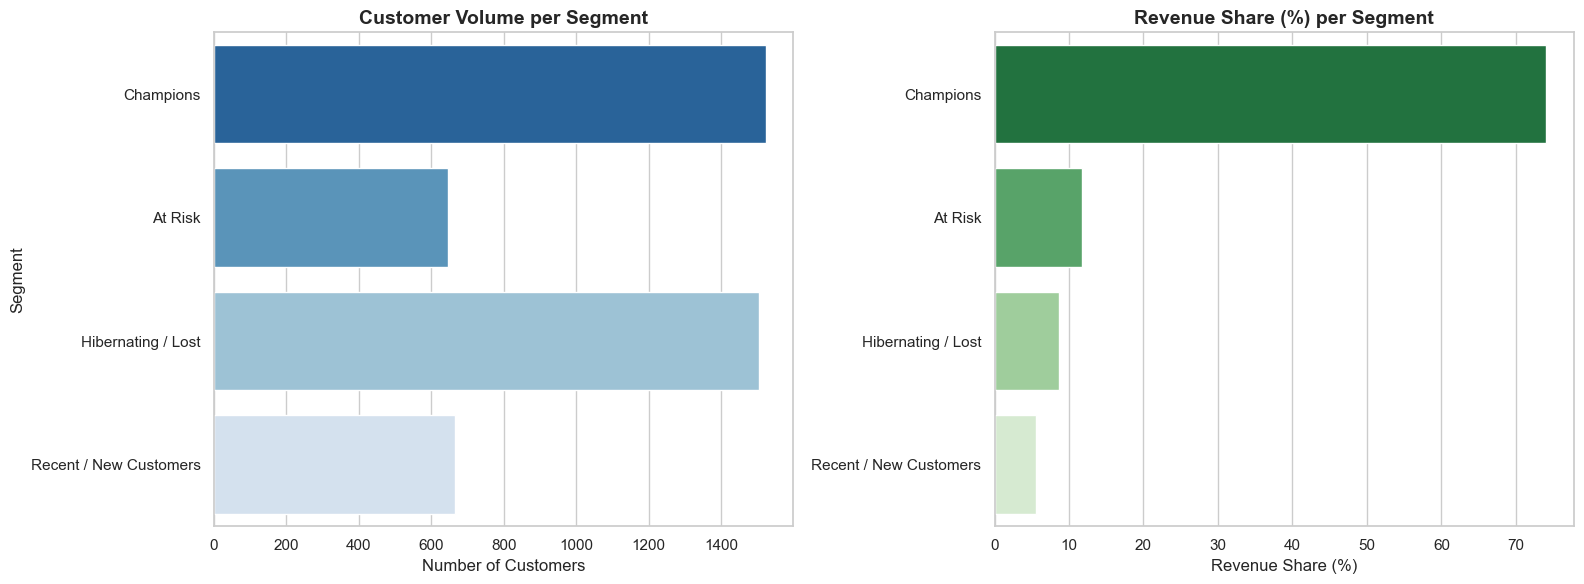


--- 3. Raw RFM Metrics Summary Statistics ---


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,1660.60
max,374.00,209.00,280206.02



--- 4. Visualizing Raw RFM Distributions (Skewness Inspection) ---


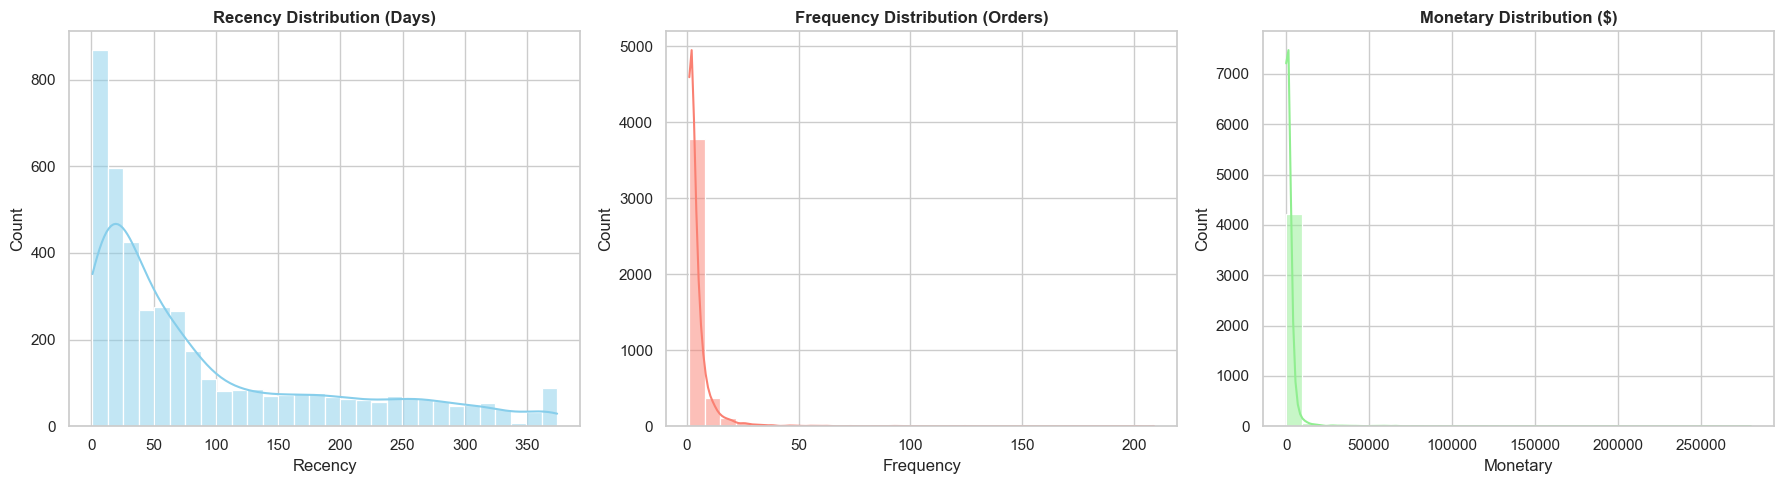


--- 5. Applying Log Transformation & Visualizing Normalization ---


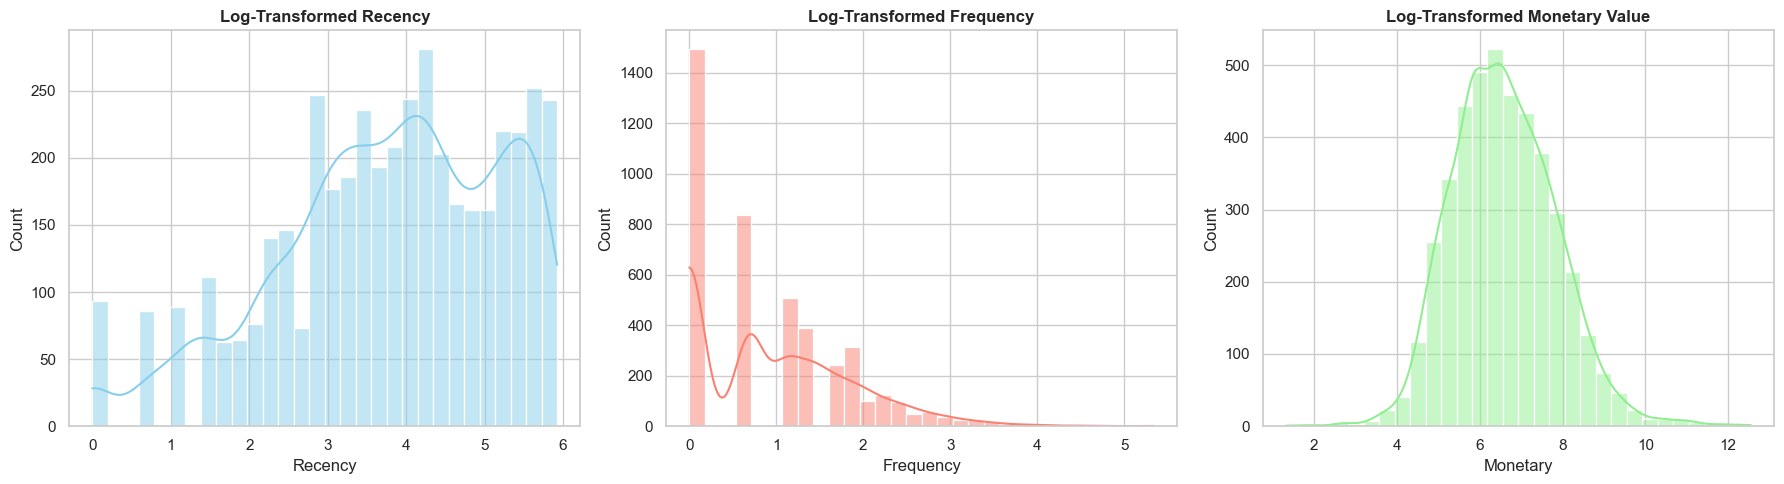

STEP 3 COMPLETED SUCCESSFULLY
 -> Generated Summary for 4 Customer Segments
 -> Log-Transformed DataFrame 'rfm_log' ready for Scaling & K-Means Clustering


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style globally
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

def run_step3_rfm_eda_and_transformations(rfm):
    """
    Performs Exploratory Data Analysis (EDA) on generated RFM segments,
    plots distribution skewness, applies log transformation for modeling, 
    and previews normalized features.
    """
    print("=" * 60)
    print("STARTING STEP 3: EXPLORATORY DATA ANALYSIS & PRE-PROCESSING")
    print("=" * 60)

    # ==========================================
    # 1. SEGMENT REVENUE & CUSTOMER SUMMARY
    # ==========================================
    print("\n--- 1. Segment Customer Counts & Revenue Summary ---")
    segment_summary = rfm.groupby('Segment').agg({
        'CustomerID': 'count',
        'Recency': 'mean',
        'Frequency': 'mean',
        'Monetary': ['mean', 'sum']
    }).round(2)

    # Flatten column names
    segment_summary.columns = ['Customer_Count', 'Avg_Recency_Days', 'Avg_Frequency', 'Avg_Monetary_$', 'Total_Monetary_$']
    
    # Calculate percentage shares
    segment_summary['Customer_Share_%'] = (segment_summary['Customer_Count'] / len(rfm) * 100).round(2)
    segment_summary['Revenue_Share_%'] = (segment_summary['Total_Monetary_$'] / rfm['Monetary'].sum() * 100).round(2)
    
    # Sort by total revenue
    segment_summary = segment_summary.sort_values(by='Total_Monetary_$', ascending=False)
    display(segment_summary)

    # ==========================================
    # 2. VISUALIZING SEGMENT DISTRIBUTIONS
    # ==========================================
    print("\n--- 2. Visualizing Customer Distribution Across Segments ---")
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Customer Count by Segment
    sns.barplot(
        data=segment_summary.reset_index(), 
        x='Customer_Count', 
        y='Segment', 
        palette='Blues_r', 
        ax=axes[0]
    )
    axes[0].set_title('Customer Volume per Segment', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Number of Customers')
    axes[0].set_ylabel('Segment')

    # Total Revenue Share by Segment
    sns.barplot(
        data=segment_summary.reset_index(), 
        x='Revenue_Share_%', 
        y='Segment', 
        palette='Greens_r', 
        ax=axes[1]
    )
    axes[1].set_title('Revenue Share (%) per Segment', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Revenue Share (%)')
    axes[1].set_ylabel('')

    plt.tight_layout()
    plt.show()

    # ==========================================
    # 3. RAW RFM METRICS SUMMARY & SKEWNESS INSPECTION
    # ==========================================
    print("\n--- 3. Raw RFM Metrics Summary Statistics ---")
    rfm_raw = rfm[['Recency', 'Frequency', 'Monetary']]
    display(rfm_raw.describe().round(2))

    print("\n--- 4. Visualizing Raw RFM Distributions (Skewness Inspection) ---")
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    sns.histplot(rfm['Recency'], bins=30, kde=True, ax=axes[0], color='skyblue')
    axes[0].set_title('Recency Distribution (Days)', fontsize=12, fontweight='bold')

    sns.histplot(rfm['Frequency'], bins=30, kde=True, ax=axes[1], color='salmon')
    axes[1].set_title('Frequency Distribution (Orders)', fontsize=12, fontweight='bold')

    sns.histplot(rfm['Monetary'], bins=30, kde=True, ax=axes[2], color='lightgreen')
    axes[2].set_title('Monetary Distribution ($)', fontsize=12, fontweight='bold')

    plt.tight_layout()
    plt.show()

    # ==========================================
    # 4. LOG TRANSFORMATION FOR UN-SKEWING DATA
    # ==========================================
    print("\n--- 5. Applying Log Transformation & Visualizing Normalization ---")
    rfm_log = np.log(rfm_raw).round(3)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    sns.histplot(rfm_log['Recency'], bins=30, kde=True, ax=axes[0], color='skyblue')
    axes[0].set_title('Log-Transformed Recency', fontsize=12, fontweight='bold')

    sns.histplot(rfm_log['Frequency'], bins=30, kde=True, ax=axes[1], color='salmon')
    axes[1].set_title('Log-Transformed Frequency', fontsize=12, fontweight='bold')

    sns.histplot(rfm_log['Monetary'], bins=30, kde=True, ax=axes[2], color='lightgreen')
    axes[2].set_title('Log-Transformed Monetary Value', fontsize=12, fontweight='bold')

    plt.tight_layout()
    plt.show()

    print("=" * 60)
    print("STEP 3 COMPLETED SUCCESSFULLY")
    print(f" -> Generated Summary for {len(segment_summary)} Customer Segments")
    print(" -> Log-Transformed DataFrame 'rfm_log' ready for Scaling & K-Means Clustering")
    print("=" * 60)

    return rfm_log

# Execute Step 3 using rfm_df from Step 2
rfm_log = run_step3_rfm_eda_and_transformations(rfm_df)

STARTING STEP 4: COHORT RETENTION & QUANTITY HEATMAPS

--- 2. Building Cohort Retention Matrix ---


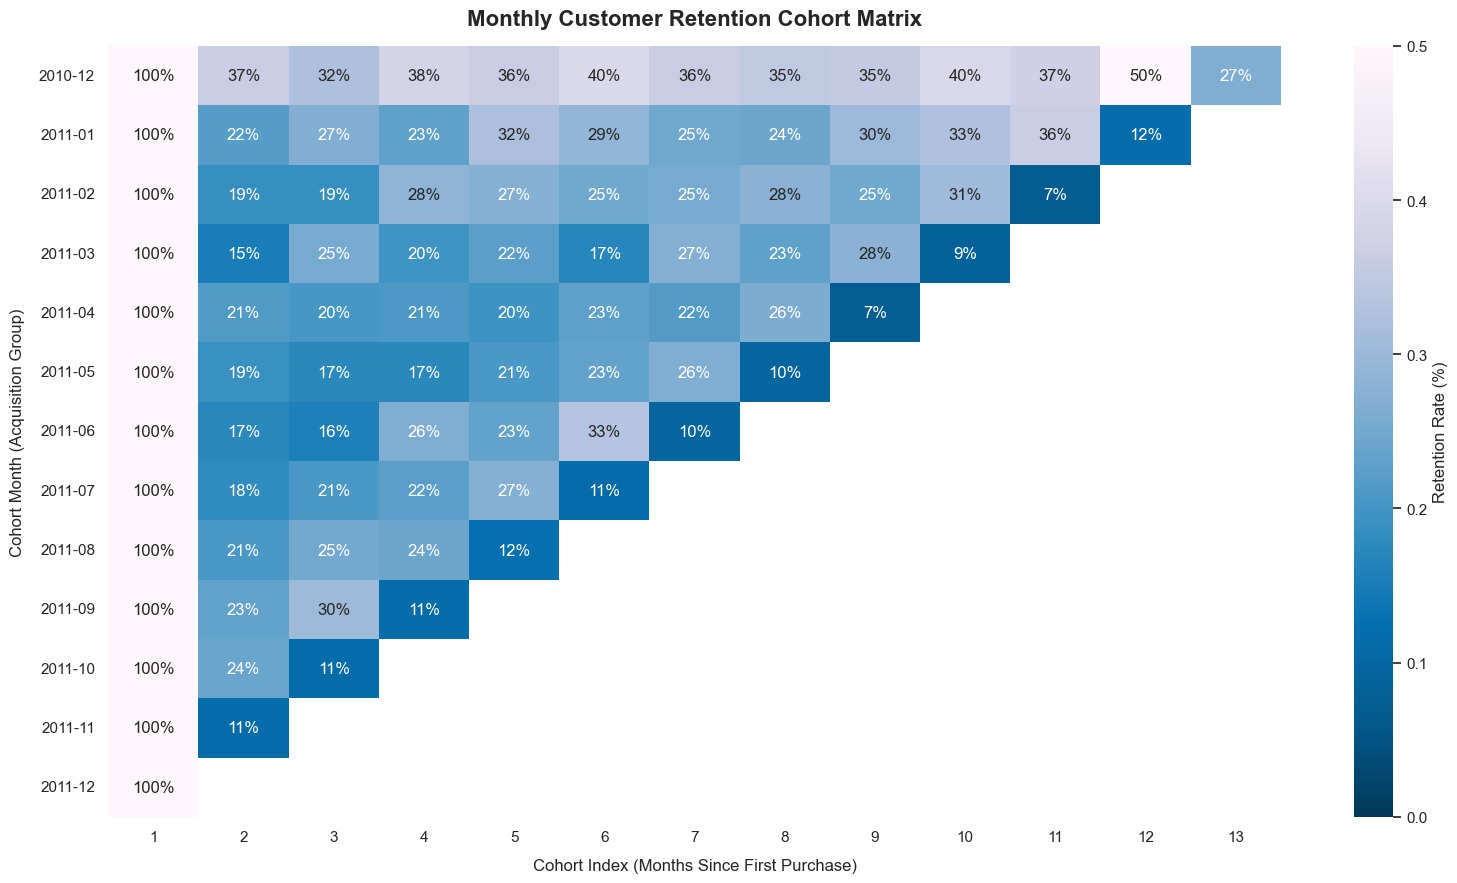


--- 3. Building Average Quantity Cohort Matrix ---


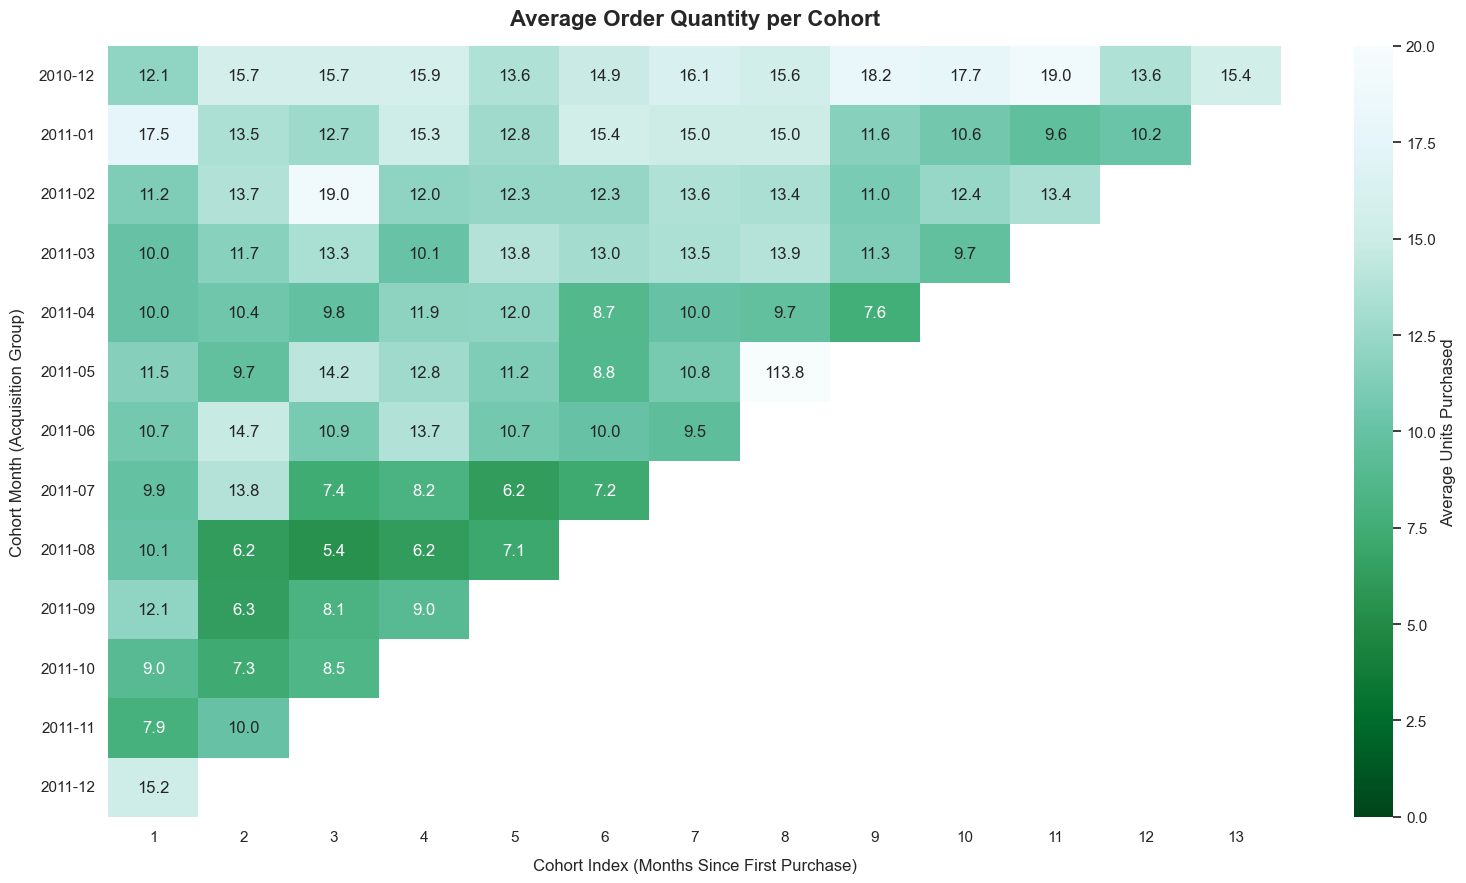

STEP 4 COMPLETED SUCCESSFULLY
 -> Evaluated 13 Cohort Groups
 -> Max Tracked Lifecycle: 13 Months


In [9]:
import pandas as pd
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="white")

def run_step4_cohort_analysis(df):
    """
    Computes monthly cohort retention rates and average order quantities,
    then displays annotated heatmaps for both metrics.
    
    Parameters:
    df (pd.DataFrame): Cleaned transaction dataframe with cohort features.
    
    Returns:
    pd.DataFrame: Cohort retention percentage matrix.
    """
    print("=" * 60)
    print("STARTING STEP 4: COHORT RETENTION & QUANTITY HEATMAPS")
    print("=" * 60)

    # Ensure Cohort Features exist on the DataFrame
    if 'CohortMonth' not in df.columns or 'CohortIndex' not in df.columns:
        print("--- 1. Generating Cohort Months & Indices ---")
        def get_month(x): 
            return dt.datetime(x.year, x.month, 1)

        df['InvoiceMonth'] = df['InvoiceDate'].apply(get_month)
        df['CohortMonth'] = df.groupby('CustomerID')['InvoiceMonth'].transform('min')

        invoice_year, invoice_month = df['InvoiceMonth'].dt.year, df['InvoiceMonth'].dt.month
        cohort_year, cohort_month = df['CohortMonth'].dt.year, df['CohortMonth'].dt.month

        years_diff = invoice_year - cohort_year
        months_diff = invoice_month - cohort_month
        df['CohortIndex'] = years_diff * 12 + months_diff + 1

    # ==========================================
    # 1. RETENTION RATE MATRIX & HEATMAP
    # ==========================================
    print("\n--- 2. Building Cohort Retention Matrix ---")
    cohort_data = df.groupby(['CohortMonth', 'CohortIndex'])['CustomerID'].nunique().reset_index()
    cohort_counts = cohort_data.pivot(index='CohortMonth', columns='CohortIndex', values='CustomerID')
    
    # Calculate retention rates relative to CohortIndex 1
    cohort_sizes = cohort_counts.iloc[:, 0]
    retention_matrix = cohort_counts.divide(cohort_sizes, axis=0)

    # Format Y-axis index to 'YYYY-MM'
    retention_matrix.index = retention_matrix.index.strftime('%Y-%m')

    # Plot Retention Heatmap
    plt.figure(figsize=(16, 9))
    sns.heatmap(
        data=retention_matrix,
        annot=True,
        fmt='.0%',
        vmin=0.0,
        vmax=0.5,       # Caps color scale at 50% for clearer contrast
        cmap='PuBu_r',
        cbar_kws={'label': 'Retention Rate (%)'}
    )
    plt.title('Monthly Customer Retention Cohort Matrix', fontsize=16, fontweight='bold', pad=15)
    plt.xlabel('Cohort Index (Months Since First Purchase)', fontsize=12, labelpad=10)
    plt.ylabel('Cohort Month (Acquisition Group)', fontsize=12, labelpad=10)
    plt.tight_layout()
    plt.show()

    # ==========================================
    # 2. AVERAGE QUANTITY MATRIX & HEATMAP
    # ==========================================
    print("\n--- 3. Building Average Quantity Cohort Matrix ---")
    cohort_qty = df.groupby(['CohortMonth', 'CohortIndex'])['Quantity'].mean().reset_index()
    average_quantity = cohort_qty.pivot(index='CohortMonth', columns='CohortIndex', values='Quantity').round(1)

    # Format Y-axis index to 'YYYY-MM'
    average_quantity.index = average_quantity.index.strftime('%Y-%m')

    # Plot Average Quantity Heatmap
    plt.figure(figsize=(16, 9))
    sns.heatmap(
        data=average_quantity,
        annot=True,
        fmt='.1f',
        vmin=0.0,
        vmax=20.0,
        cmap='BuGn_r',
        cbar_kws={'label': 'Average Units Purchased'}
    )
    plt.title('Average Order Quantity per Cohort', fontsize=16, fontweight='bold', pad=15)
    plt.xlabel('Cohort Index (Months Since First Purchase)', fontsize=12, labelpad=10)
    plt.ylabel('Cohort Month (Acquisition Group)', fontsize=12, labelpad=10)
    plt.tight_layout()
    plt.show()

    print("=" * 60)
    print("STEP 4 COMPLETED SUCCESSFULLY")
    print(f" -> Evaluated {len(retention_matrix)} Cohort Groups")
    print(f" -> Max Tracked Lifecycle: {retention_matrix.shape[1]} Months")
    print("=" * 60)

    return retention_matrix

# Execute Step 4
retention_matrix = run_step4_cohort_analysis(clean_df)

STARTING STEP 5: K-MEANS CLUSTERING & SNAKE PLOT ANALYTICS

--- 2. Evaluating Optimal Clusters (Elbow Method) ---


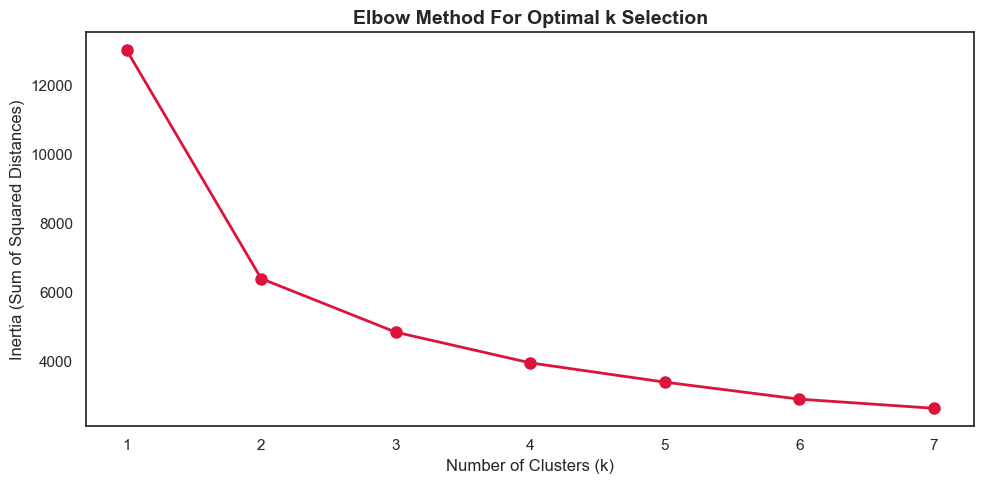


--- K-Means Cluster Profiles Summary ---


Recency Frequency Monetary      
             mean      mean     mean count
K_Cluster                                 
0            55.4       3.4   1318.4  1689
1            13.9      12.7   7351.6   823
2           162.3       1.3    334.1  1826

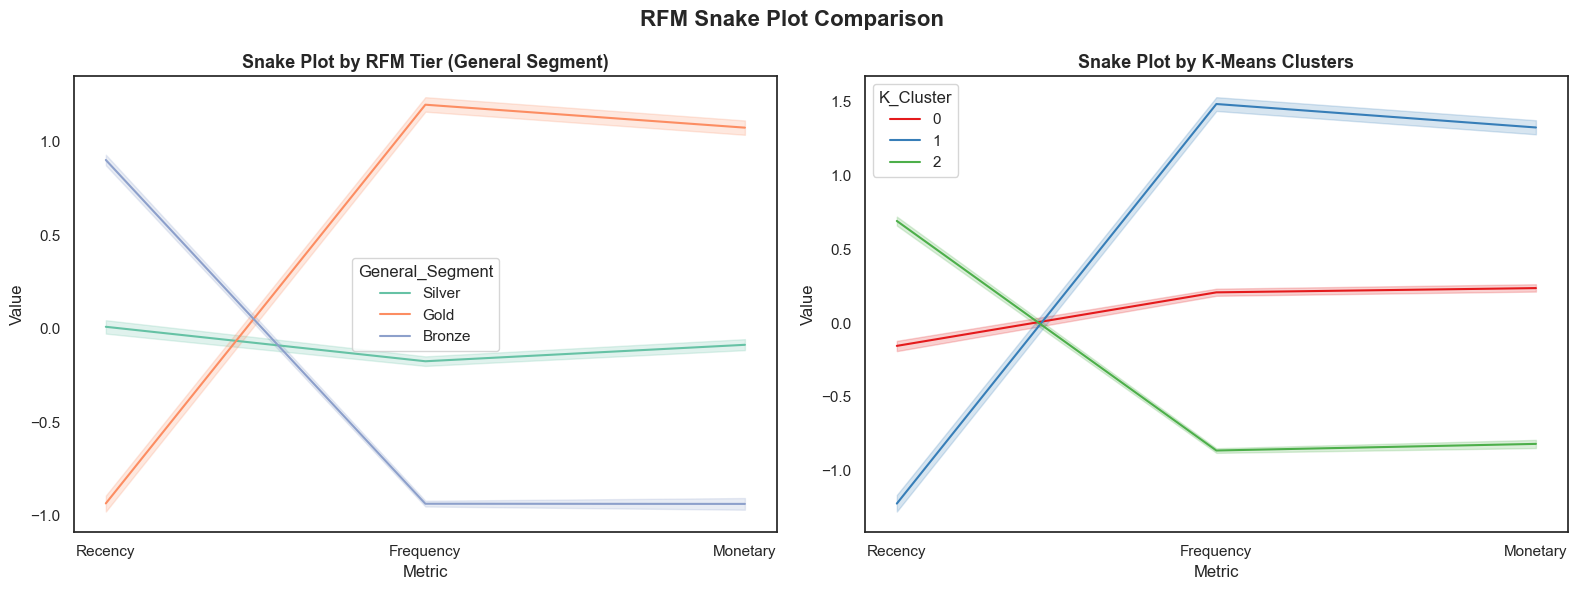

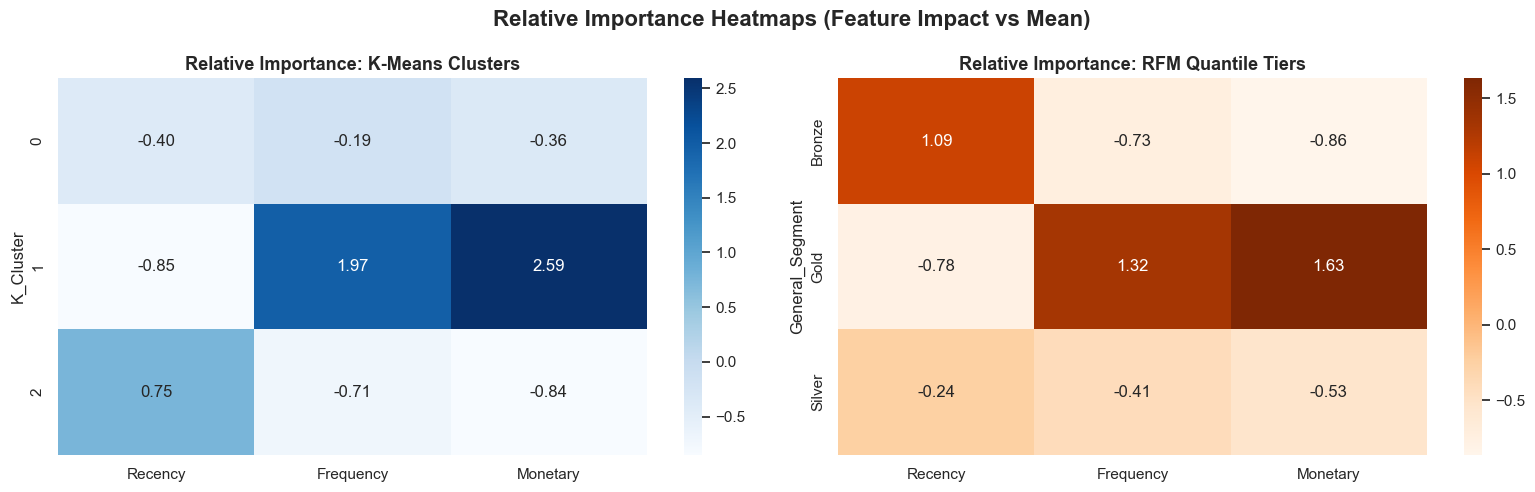

STEP 5 COMPLETED SUCCESSFULLY


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

print("=" * 60)
print("STARTING STEP 5: K-MEANS CLUSTERING & SNAKE PLOT ANALYTICS")
print("=" * 60)

# ==========================================
# 1. NORMALIZE VARIABLES WITH STANDARDSCALER
# ==========================================
rfm_features = rfm_df[['Recency', 'Frequency', 'Monetary']]

scaler = StandardScaler()
scaler.fit(rfm_log)
rfm_normalized_array = scaler.transform(rfm_log)

# ==========================================
# 2. ELBOW METHOD FOR OPTIMAL KMEANS CLUSTERS
# ==========================================
print("\n--- 2. Evaluating Optimal Clusters (Elbow Method) ---")
ks = range(1, 8)
inertias = []

for k in ks:
    kc = KMeans(n_clusters=k, random_state=42)
    kc.fit(rfm_normalized_array)
    inertias.append(kc.inertia_)

# Plot Inertia vs. Number of Clusters
plt.figure(figsize=(10, 5))
plt.plot(ks, inertias, '-o', color='crimson', linewidth=2, markersize=8)
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Inertia (Sum of Squared Distances)', fontsize=12)
plt.title('Elbow Method For Optimal k Selection', fontsize=14, fontweight='bold')
plt.xticks(ks)
plt.tight_layout()
plt.show()

# ==========================================
# 3. K-MEANS CLUSTERING (k=3)
# ==========================================
kc = KMeans(n_clusters=3, random_state=1)
kc.fit(rfm_normalized_array)

rfm_rfm_k3 = rfm_features.assign(K_Cluster=kc.labels_)

print("\n--- K-Means Cluster Profiles Summary ---")
display(
    rfm_rfm_k3.groupby('K_Cluster')
    .agg({
        'Recency': 'mean',
        'Frequency': 'mean',
        'Monetary': ['mean', 'count'],
    })
    .round(1)
)

# ==========================================
# 4. PREPARE MELTED DATASET FOR SNAKE PLOTS
# ==========================================
rfm_normalized_df = pd.DataFrame(
    rfm_normalized_array, index=rfm_df['CustomerID'], columns=['Recency', 'Frequency', 'Monetary']
)
rfm_normalized_df['K_Cluster'] = kc.labels_
rfm_normalized_df['General_Segment'] = rfm_df['General_Segment'].values
rfm_normalized_df.reset_index(inplace=True)

rfm_melt = pd.melt(
    rfm_normalized_df,
    id_vars=['CustomerID', 'General_Segment', 'K_Cluster'],
    value_vars=['Recency', 'Frequency', 'Monetary'],
    var_name='Metric',
    value_name='Value',
)

# ==========================================
# 5. SNAKE PLOT VISUALIZATIONS
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

sns.lineplot(x='Metric', y='Value', hue='General_Segment', data=rfm_melt, ax=ax1, palette='Set2')
ax1.set_title('Snake Plot by RFM Tier (General Segment)', fontsize=13, fontweight='bold')

sns.lineplot(x='Metric', y='Value', hue='K_Cluster', data=rfm_melt, ax=ax2, palette='Set1')
ax2.set_title('Snake Plot by K-Means Clusters', fontsize=13, fontweight='bold')

plt.suptitle("RFM Snake Plot Comparison", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# ==========================================
# 6. RELATIVE IMPORTANCE CALCULATION
# ==========================================
cluster_avg = rfm_rfm_k3.groupby(['K_Cluster']).mean()
population_avg = rfm_features.mean()
relative_imp = (cluster_avg / population_avg - 1).round(2)

total_avg = rfm_features.mean()
cluster_avg_segment = rfm_df.groupby('General_Segment')[['Recency', 'Frequency', 'Monetary']].mean()
prop_rfm = (cluster_avg_segment / total_avg - 1).round(2)

# ==========================================
# 7. HEATMAP COMPARISON VISUALIZATION
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

sns.heatmap(data=relative_imp, annot=True, fmt='.2f', cmap='Blues', ax=ax1)
ax1.set_title("Relative Importance: K-Means Clusters", fontsize=13, fontweight='bold')

sns.heatmap(data=prop_rfm, annot=True, fmt='.2f', cmap='Oranges', ax=ax2)
ax2.set_title("Relative Importance: RFM Quantile Tiers", fontsize=13, fontweight='bold')

plt.suptitle("Relative Importance Heatmaps (Feature Impact vs Mean)", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("=" * 60)
print("STEP 5 COMPLETED SUCCESSFULLY")
print("=" * 60)